# Exploratory Data Analysis: E-commerce Orders
**Goal:** Analyze the orders dataset (1,200 records) to understand patterns, trends, distributions and outliers.

In [21]:
#importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [22]:
#Reading the excel file and converting it to dataframe
df=pd.read_excel("Cleaned_Dataset.xlsx")
df1=pd.DataFrame(df)
df1.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [23]:
df.describe()

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,356.412750,5.485000,1053.968300
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
25%,2.000000,186.062500,4.000000,410.520000
50%,3.000000,364.210000,5.000000,823.615000
75%,4.000000,521.570000,7.000000,1578.475000
max,5.000000,699.930000,10.000000,3456.400000


In [24]:
df.isnull().sum()

,0
OrderID,0
Date,0
CustomerID,0
Product,0
Quantity,0
UnitPrice,0
ShippingAddress,0
PaymentMethod,0
OrderStatus,0
TrackingNumber,0


In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
# Calculating the mean and median for Numeric columns
for col in ['Quantity', 'UnitPrice', 'ItemsInCart', 'TotalPrice']:
    print(col)
    print("  Mean  :", df[col].mean())
    print("  Median:", df[col].median())
    print("  Count :", df[col].count())

Quantity
  Mean  : 2.9458333333333333
  Median: 3.0
  Count : 1200
UnitPrice
  Mean  : 356.41275
  Median: 364.21
  Count : 1200
ItemsInCart
  Mean  : 5.485
  Median: 5.0
  Count : 1200
TotalPrice
  Mean  : 1053.9683
  Median: 823.615
  Count : 1200


In [27]:
#Calculating the Mode for Categorical column
for col in ['Product', 'PaymentMethod', 'OrderStatus', 'CouponCode', 'ReferralSource']:
    print(col,"Mode:-")
    print(df[col].mode()[0],"\n")


Product Mode:-
Printer 

PaymentMethod Mode:-
Online 

OrderStatus Mode:-
Cancelled 

CouponCode Mode:-
FREESHIP 

ReferralSource Mode:-
Instagram 



In [28]:
#identifying outliers
#IQR method is used because it is robust to skewed business data like TotalPrice.
for col in ['Quantity', 'UnitPrice', 'ItemsInCart', 'TotalPrice']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(col, "-> Outliers:", len(outliers))



Quantity -> Outliers: 0
UnitPrice -> Outliers: 0
ItemsInCart -> Outliers: 0
TotalPrice -> Outliers: 8


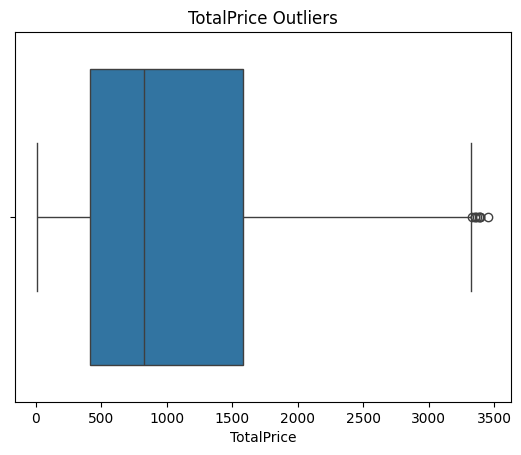

In [29]:
# Boxplot
sns.boxplot(x=df['TotalPrice'])
plt.title("TotalPrice Outliers")
plt.show()

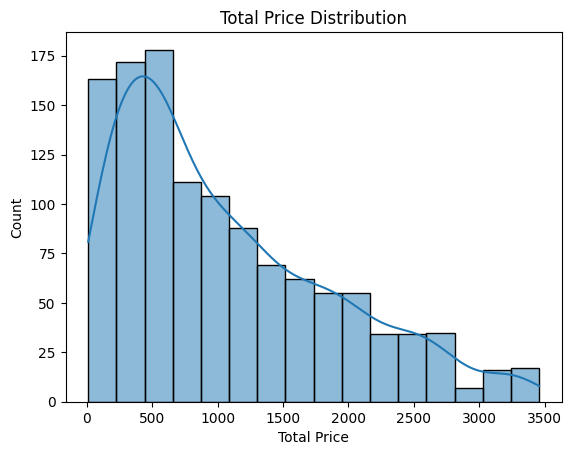

In [30]:
sns.histplot(df['TotalPrice'], kde=True)
plt.title("Total Price Distribution")
plt.xlabel("Total Price")
plt.ylabel("Count")
plt.show()

      Orders    Revenue     AvgOrder
Year                                
2023     510  552643.24  1083.614196
2024     459  480235.87  1046.265512
2025     231  231882.85  1003.821861


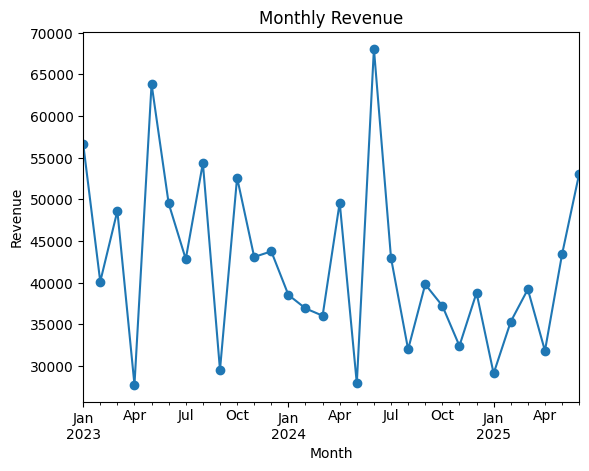

OrderStatus
Cancelled    20.833333
Returned     20.583333
Pending      19.750000
Shipped      19.583333
Delivered    19.250000
Name: proportion, dtype: float64


In [31]:
# Identifying Trends

# Convert the Date column to datetime so we can extract year/month from it
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year

# Yearly trend: number of orders, total revenue and average order value per year
yearly = df.groupby('Year').agg(Orders=('OrderID', 'count'),
                                Revenue=('TotalPrice', 'sum'),
                                AvgOrder=('TotalPrice', 'mean'))
print(yearly)

# Monthly trend: total revenue for each month, shown as a line chart
monthly = df.groupby(df['Date'].dt.to_period('M'))['TotalPrice'].sum()
monthly.plot(marker='o', title="Monthly Revenue")
plt.xlabel("Month")       # label for the x-axis
plt.ylabel("Revenue")     # label for the y-axis
plt.show()

# Order status breakdown: percentage share of each status
print(df['OrderStatus'].value_counts(normalize=True) * 100)

In [32]:
  # Check skewness: close to 0 = symmetric, positive = right-skewed
print(df[['Quantity', 'UnitPrice', 'ItemsInCart', 'TotalPrice']].skew())

Quantity       0.027922
UnitPrice     -0.026512
ItemsInCart    0.000877
TotalPrice     0.891359
dtype: float64


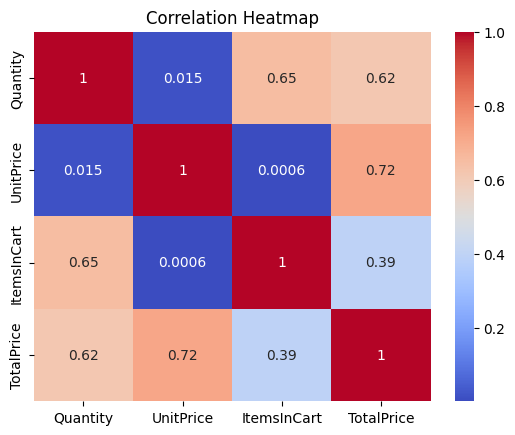

In [33]:
# Correlation between numeric columns
sns.heatmap(df[['Quantity', 'UnitPrice', 'ItemsInCart', 'TotalPrice']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

## Key Observations

1. **Dataset size:** 1,200 orders. No outliers in Quantity, UnitPrice or ItemsInCart.
2. **Skewed revenue:** TotalPrice mean (1053.97) is higher than the median (823.62), and skewness is 0.89, so it is right-skewed. The median is the better "typical order" value.
3. **Distribution shape:** The histogram confirms TotalPrice is right-skewed: most orders are low-value, with a few high-value orders pulling the mean up.
4. **Outliers:** 8 high-value orders in TotalPrice (IQR method). Worth investigating as possible bulk or VIP buyers rather than deleting them.
5. **Yearly trend:** Revenue fell from 552,643 (2023) to 480,236 (2024). 2025 is a partial year (231 orders), so compare average order value instead: 1083 → 1046 → 1003, a slight steady decline.
6. **Monthly trend:** Revenue is very volatile (roughly 28k to 68k per month) with no clear seasonality.
7. **Order status:** Cancelled (20.8%) and Returned (20.6%) together are about 41% of orders. Only 19.3% were Delivered.
8. **Correlation:** TotalPrice is most strongly related to UnitPrice (0.72) and Quantity (0.62). Quantity and ItemsInCart are also moderately related (0.65). Correlation is not causation.
9. **Expected relationship:** TotalPrice = Quantity × UnitPrice (e.g., 5 × 570.62 = 2853.10), so its correlation with those two columns is expected by definition and not a new insight.
10. **Most common values:** Product = Printer, Payment = Online, Coupon = FREESHIP, Referral = Instagram.

## So what?
About 4 in 10 orders are cancelled or returned. Finding out why is the first priority, because it directly affects revenue.